In [3]:

import pandas as pd

raw = pd.read_csv("/content/T_ONTIME_REPORTING.csv")
arrival = pd.read_csv("/content/ord_arrival_dataset.csv")
departure = pd.read_csv("/content/ord_departure_dataset.csv")


In [4]:

congestion_cols = [
    "SCHEDULED_DEPARTURES",
    "SCHEDULED_ARRIVALS",
    "TOTAL_SCHEDULED_TRAFFIC"
]

# 1. Arrival congestion summary
print("=== ARRIVAL CONGESTION ===")
display(arrival[congestion_cols].describe())

# 2. Departure congestion summary
print("=== DEPARTURE CONGESTION ===")
display(departure[congestion_cols].describe())

# 3. Check whether total = departure + arrival
for name, df in [
    ("Arrival", arrival),
    ("Departure", departure)
]:
    mismatch = (
        df["SCHEDULED_DEPARTURES"] +
        df["SCHEDULED_ARRIVALS"] !=
        df["TOTAL_SCHEDULED_TRAFFIC"]
    )

    print(f"{name} total traffic mismatches: {mismatch.sum()}")

# 4. Check number of unique congestion values
for name, df in [
    ("Arrival", arrival),
    ("Departure", departure)
]:
    print(f"\n{name} unique values:")
    print(df[congestion_cols].nunique())


=== ARRIVAL CONGESTION ===


,SCHEDULED_DEPARTURES,SCHEDULED_ARRIVALS,TOTAL_SCHEDULED_TRAFFIC
count,24019.000000,24019.000000,24019.000000
mean,48.717141,56.484491,105.201632
std,15.551371,23.490913,31.851947
min,0.000000,5.000000,7.000000
25%,41.000000,43.000000,90.000000
50%,48.000000,56.000000,106.000000
75%,60.000000,67.000000,117.000000
max,81.000000,114.000000,164.000000


=== DEPARTURE CONGESTION ===


,SCHEDULED_DEPARTURES,SCHEDULED_ARRIVALS,TOTAL_SCHEDULED_TRAFFIC
count,24192.000000,24192.000000,24192.000000
mean,53.581556,48.813368,102.394924
std,14.118845,22.045571,26.647196
min,1.000000,5.000000,10.000000
25%,44.000000,30.000000,88.000000
50%,53.000000,50.000000,103.000000
75%,64.000000,62.000000,115.000000
max,81.000000,114.000000,164.000000


Arrival total traffic mismatches: 0
Departure total traffic mismatches: 0

Arrival unique values:
SCHEDULED_DEPARTURES        73
SCHEDULED_ARRIVALS          90
TOTAL_SCHEDULED_TRAFFIC    111
dtype: int64

Departure unique values:
SCHEDULED_DEPARTURES        72
SCHEDULED_ARRIVALS          90
TOTAL_SCHEDULED_TRAFFIC    109
dtype: int64


In [5]:

arr_check = arrival.copy()
dep_check = departure.copy()

arr_check["HOUR"] = (
    arr_check["CRS_ARR_TIME"] // 100
)

dep_check["HOUR"] = (
    dep_check["CRS_DEP_TIME"] // 100
)

print("Arrival hours:")
print(sorted(arr_check["HOUR"].unique()))

print("\nDeparture hours:")
print(sorted(dep_check["HOUR"].unique()))

for name, df in [
    ("Arrival", arr_check),
    ("Departure", dep_check)
]:
    consistency = (
        df.groupby(["FL_DATE", "HOUR"])[
            congestion_cols
        ]
        .nunique()
    )

    inconsistent = (
        consistency > 1
    ).any(axis=1)

    print(f"\n{name}")
    print("Date-hour groups:", len(consistency))
    print("Inconsistent groups:", inconsistent.sum())


Arrival hours:
[np.int64(0), np.int64(1), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]

Departure hours:
[np.int64(0), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]

Arrival
Date-hour groups: 630
Inconsistent groups: 0

Departure
Date-hour groups: 541
Inconsistent groups: 0


In [6]:

import pandas as pd
import matplotlib.pyplot as plt

arr_summary = (
    arrival.groupby("TOTAL_SCHEDULED_TRAFFIC")
    .agg(
        mean_delay=("ARR_DELAY", "mean"),
        median_delay=("ARR_DELAY", "median"),
        n=("ARR_DELAY", "size")
    )
    .reset_index()
)


dep_summary = (
    departure.groupby("TOTAL_SCHEDULED_TRAFFIC")
    .agg(
        mean_delay=("DEP_DELAY", "mean"),
        median_delay=("DEP_DELAY", "median"),
        n=("DEP_DELAY", "size")
    )
    .reset_index()
)

display(arr_summary.head())
display(dep_summary.head())


,TOTAL_SCHEDULED_TRAFFIC,mean_delay,median_delay,n
0,7,13.166667,6.5,18
1,8,-5.375000,-12.0,8
2,10,-3.794118,-12.5,68
3,11,0.766667,-10.5,90
4,13,8.252252,-8.0,222


,TOTAL_SCHEDULED_TRAFFIC,mean_delay,median_delay,n
0,10,-0.517241,-5.0,29
1,11,-6.400000,-6.0,5
2,13,11.050000,-2.0,20
3,14,15.297297,-3.0,37
4,15,-1.735294,-3.5,34


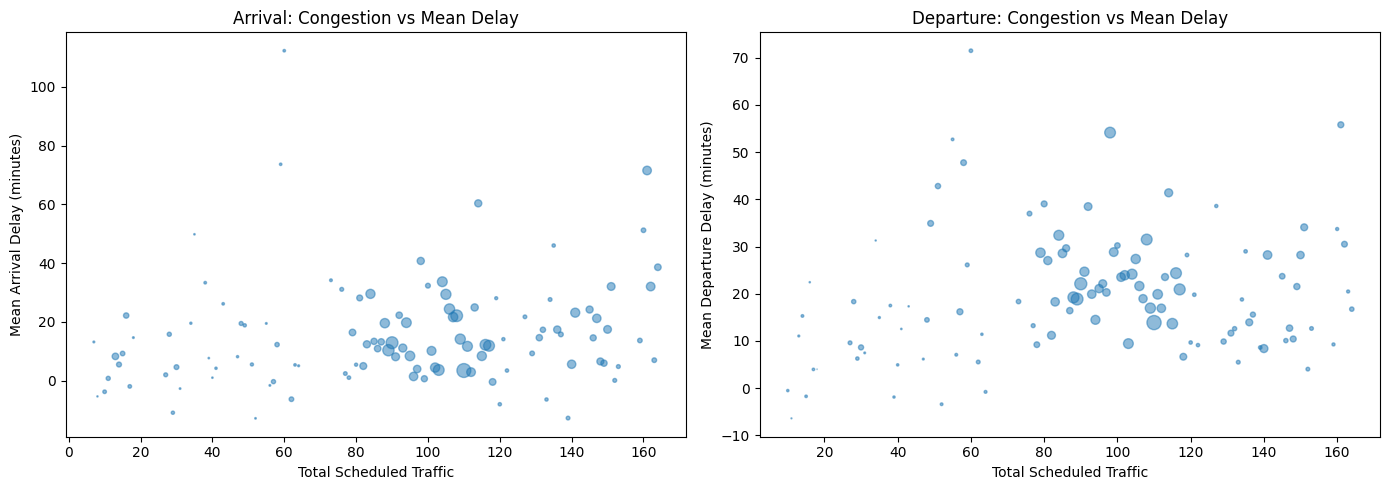

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Arrival
axes[0].scatter(
    arr_summary["TOTAL_SCHEDULED_TRAFFIC"],
    arr_summary["mean_delay"],
    s=arr_summary["n"] / 10,
    alpha=0.5
)
axes[0].set_title("Arrival: Congestion vs Mean Delay")
axes[0].set_xlabel("Total Scheduled Traffic")
axes[0].set_ylabel("Mean Arrival Delay (minutes)")

# Departure
axes[1].scatter(
    dep_summary["TOTAL_SCHEDULED_TRAFFIC"],
    dep_summary["mean_delay"],
    s=dep_summary["n"] / 10,
    alpha=0.5
)
axes[1].set_title("Departure: Congestion vs Mean Delay")
axes[1].set_xlabel("Total Scheduled Traffic")
axes[1].set_ylabel("Mean Departure Delay (minutes)")

plt.tight_layout()
plt.show()


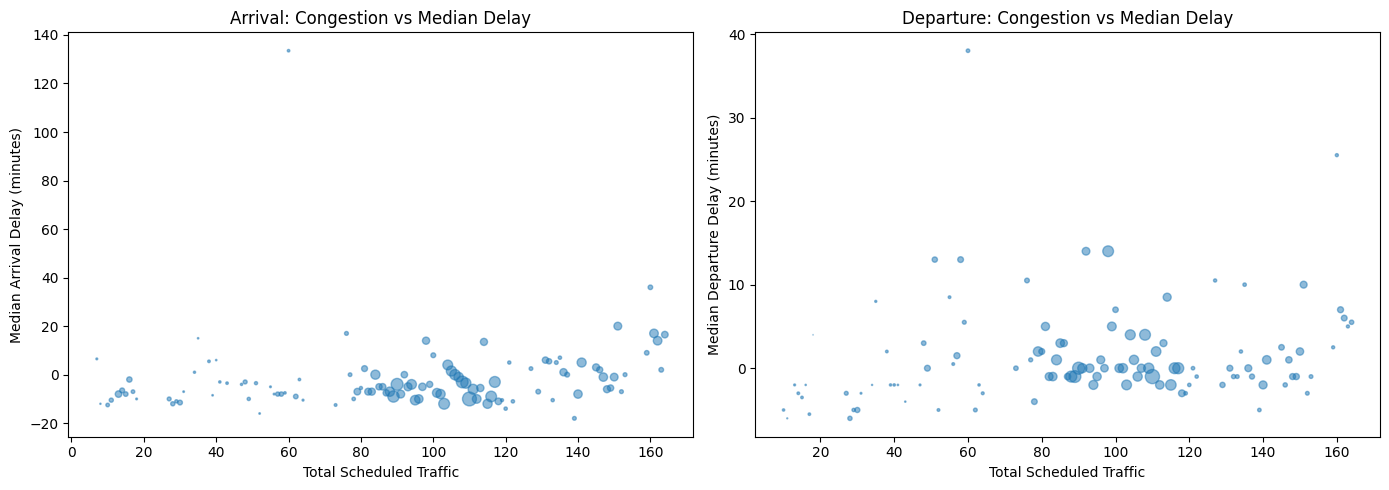

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    arr_summary["TOTAL_SCHEDULED_TRAFFIC"],
    arr_summary["median_delay"],
    s=arr_summary["n"] / 10,
    alpha=0.5
)
axes[0].set_title("Arrival: Congestion vs Median Delay")
axes[0].set_xlabel("Total Scheduled Traffic")
axes[0].set_ylabel("Median Arrival Delay (minutes)")

axes[1].scatter(
    dep_summary["TOTAL_SCHEDULED_TRAFFIC"],
    dep_summary["median_delay"],
    s=dep_summary["n"] / 10,
    alpha=0.5
)
axes[1].set_title("Departure: Congestion vs Median Delay")
axes[1].set_xlabel("Total Scheduled Traffic")
axes[1].set_ylabel("Median Departure Delay (minutes)")

plt.tight_layout()
plt.show()


In [9]:

from scipy.stats import pearsonr, spearmanr

for name, df, delay_col in [
    ("Arrival", arrival, "ARR_DELAY"),
    ("Departure", departure, "DEP_DELAY")
]:
    x = df["TOTAL_SCHEDULED_TRAFFIC"]
    y = df[delay_col]

    pearson_r, pearson_p = pearsonr(x, y)
    spearman_r, spearman_p = spearmanr(x, y)

    print(f"\n=== {name} ===")
    print(f"Pearson r: {pearson_r:.4f}")
    print(f"Pearson p-value: {pearson_p:.4g}")
    print(f"Spearman rho: {spearman_r:.4f}")
    print(f"Spearman p-value: {spearman_p:.4g}")



=== Arrival ===
Pearson r: 0.0488
Pearson p-value: 3.652e-14
Spearman rho: 0.0822
Spearman p-value: 2.926e-37

=== Departure ===
Pearson r: -0.0039
Pearson p-value: 0.5454
Spearman rho: 0.0135
Spearman p-value: 0.03575
